- Recording: Analog vs Digital
    - Sampling 
    - Waves as displacements over time 
    - Derivation of sine/cosine representation by sampling tuning fork



TODO

- Intuitive interpretation of matrix multiplication as change of basis: "New x is z times old, new y is ... etc.". This is what the matrix multiplication is saying. Because I can figure out _each new axis with only its corresponding partner in the input_, i can deal with _everything separately_, in turn. _You can't do this with non-orthogonal matrices_.
  - Like if I give you straght line directions to a hotel in NYC. I pull out a map, label the landmarks, and draw straight lines between them; in my $xy$-coordinates, it's straight lines between checkpoints. But you walk; you need to think in Manhattan distances on the grid. It would have been better to just give you a path in terms of the streets, so you don't have to translate.
- If I give you directions in _my_ coordinates, they break once the grid changes. Now, if you keep going in the direction we called "straight", you have to stop, at every block, and figure out _how far in both directions you went_. This becomes expensive and error prone; it would be much easier if you could just shift the directions to the new grid.
- You can:
  - Move the aove here; scenario is: We give you directions to get someplace, but wher we are standing, there is a road that extends left/right (like x-axis); and one that extends to the "northeast", 30 degrees off the road we're on. We use these two roads are our basis vectors; interlocutor needs to walk up the 30 degree street anyway. But then after a mile, it becomes a standard grid. Now, when we follow the new grid path, we have to _stop and check_ how far we've moved on our original line, and map our position back to our original coordinates. It would be easier if we cold just switch them over once and for all.
  - This happens because, in this new grid system, the "basis" we chose _is not orthogonal_; it can generate a path to the destination, but since it "mixes" the directions in which we're constrained to move, actually measuring movement is complicated, because it's an "unnatural" _representation_ of where we actually are.
- You'd do this by taking your line and _projecting_ it onto the grid: Everywhere it casts a shadow is a step.
  - This is, specifically, the transformation from $L_{2}$ to $L_{1}$, the "taxicab transformation", that projects lines in "free" Euclidean space into grid-constrained paths.
- The intersections of the grid are at 90 degree angles. That means that we have options to get to our destination: We can move all x units right, then all y units up; or "mix and match" to get around road blocks. The point is, if I move some distance horizontally, it has _no effect_ on how far I have to move vertically; I can deal with both separately.
  - If they _weren't_, every step I take would _also_ affect how far I have left to go vertically; imagine walking a diagonal road through Manhattan. You have to adjust _both_ how far up/down _and_ left/right you go. Annoying.

This is the advantage to orthogonal matrices. I can take "directions" you've provided, that are valid where _you_ are, and convert them, _piece by piece_, into a series of directions that make sense to me. The translation doesn't destroy information, so I can always translate _back_ to your terms if I need to.

TODO

- DFT is literally a vibe check.
- The "check" happens to be the dot product: if i take every piece of me, with every piece of you, add em up, and it's _not nothing_, it's a match.
- We collect the matches, order them, and ghost what we don't like (LPF).

Let's consider what we're trying to do: Classify vowels. I.e., distinguish "a" from "o".

Naturally, this means identifying characteristics that vary across vowels. In machine learning terms, these are called **features**.

Our features are **formant frequencies**. Recall that vowels are sustained sounds produced with minimal tension in the vocal tract. The quality of different vowels depends on how the free-flowing air resonates in the mouth. In turn, the nature of this resonance is determined by the shape of your mouth.

Not that you need to, but prove it to yourself: Say "a"; then say "o", without stopping the flow of air; and notice that 1. the only way to do so is the change the shape of your mouth 2. nothing happens elsewhere in the mouth or throat.

"Resonance" refers to the way the air "bounces around" in the mouth in a wave pattern. When the mouth is shaped for an "a", the distances between the tongue and cheeks, etc., is different than when the mouth is shaped for an "o". The difference in shape creates a difference in how much space air has to bounce back and forth, which is what changes the sound.

The amount of space air has to bounce back and forth in this wave pattern determines the wave _length_—**wavelength**—of the moving air.

Wavelength, in turn, determine **frequency**, which we perceive as **pitch**.

Different mouth shapes lead to different combinations of shapes in which waves can bounce back and forth. Each pocket in which a wave does so produces a specific frequency. The set of different frequencies determines a vowel. The differences between in these frequencies are what we perceive as differences between vowels.

Because physics, there are actually an infinite number of ways for air to resonate in the mouth; so, there are an infinite number of frequencies in any vowel's "set".

Fortunately, only the first three matter much for humans.

This all means: You can think of vowels as sounds produced by combining three characteristic frequencies, called **formant frequencies**. Put together the right formant frequencies in someone's mouth<sup>1</sup>, and _voilà_: You have a vowel.

---

1. There's a reason we say it like this; we'll see an example of generating vowels by playing sounds through a tube in someone's mouth while they shape it. They generate vowels, but without their lungs; your mouth doesn't care _where_ the sound comes from. Just that there's moving air for it to shape.

...Let's take a step back. This means two things:

- If we know the three formant frequencies that make up a vowel, we should be able to mix sounds at that frequency to create a new sound similar to the vowel.
- If we could take a recording of a vowel sound, and turn it into a picture of _frequencies_, we could tell which vowel we're looking at _without hearing it_. We could just look at the frequencies in the picture; match them against a chart of known formant values; and have our answer.

It sounds hard to take a recording and turn it into a picture of frequencies. Because it is: We'll...Come back to that.

The other problem, though, seems easier. Especially for us: the Hillenbrand data literally _hands_ us formant values. If we're clever, it seems like we should be able to use those to recreate something like the vowel we heard.

Like we discussed, vowels are formed when waves in the mouth resonant together. Distinguishing vowels requires us to care about only three major resonances: the F1-3 formant frequencies. The Hillenbrand data includes F4, so we'll use it where present, but it's often omitted.

Our first guess might be: If we make one sound wave for each formant frequency, and mix them together, we might get the vowel back.

Let's try it.

First, let's get the steady-state formant frequencies for the example we heard above.

In [49]:
df.iloc[0][['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']]

f0_ss       174
f1_ss       663
f2_ss    2012.0
f3_ss    2659.0
f4_ss    3691.0
Name: 0, dtype: object

Next, we need to use these to create sound waves at these frequencies. 

Remember: A sound wave happens when air moves. If you measure how much the air is moving, and make a plot, you get the amplitude chart we looked at before.

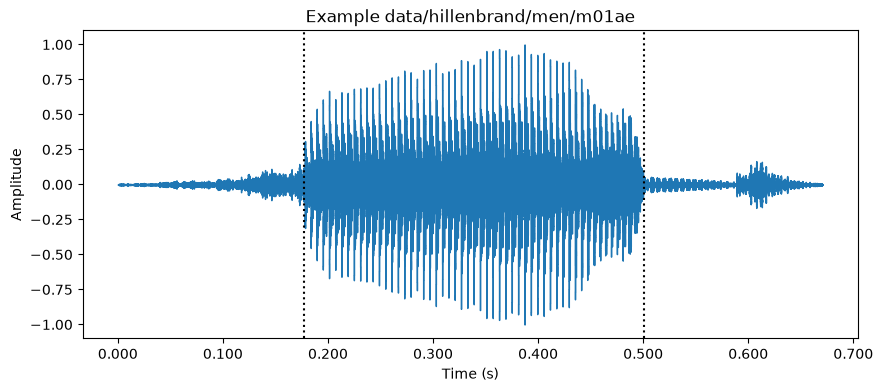

In [50]:
# Create the plot
fig, ax = plt.subplots(figsize=(10, 4))
lb.display.waveshow(audio, sr=sr, ax=ax)

# Add labels and show
ax.set(title=f'Example {example}', xlabel="Time (s)", ylabel="Amplitude")
plt.axvline(x=df_timedata['start'].iloc[0] / 1000, color='black', linestyle='dotted')
plt.axvline(x=df_timedata['end'].iloc[0] / 1000, color='black', linestyle='dotted')
plt.show()

The picture is not the sound, of course. To make the picture, we _measure_ how much the air moves around a sensor at each point in time; record those distances; and end up with a list of numbers representing how much the air moved. We have to make a lot of measurements—usually 44,100 per second—but really, you can make as many or as few as you'd like. You just lose more information the less you listen.

The trick is this: If we have that list of numbers, we can use it to make a speaker _move the air the same amount_. That way, we can use our measurements to _recreate the original sound_.

That's what's actually inside of our `audio` object: Just numbers.

In [51]:
audio

array([ 0.00048828,  0.00048828,  0.00097656, ...,  0.00048828,
       -0.00097656,  0.        ], shape=(10730,), dtype=float32)

To make sounds with the formant frequencies above, we'll make a picture that shows how the air should move. Really, we'll make a list of numbers using some math we already know, but the principle is to make the picture.

Then, we'll use that to tell the speaker how to move the air to make the sound.

Basically: All we need to do recreate our vowel is...Make the right list of numbers.

That's all we're doing here.

Now, we _do_ have to make some decisions.

- Each sound will last for **3 seconds**.
- We'll start by making every formant equally loud, with amplitudes of `0.2` (arbitrary).
- We'll assume 44,100 recordings, or **samples**, per second; number of samples per second is called the **sampling rate**.

In [52]:
# 1. constants
duration = 3.0
amplitude = 0.2
sample_rate = 44100

I'd be doing you dirty to just slip sample rate in there like that. It's the number of times we record how much the air moves around our microphone, per second. But why 44,100?

Let's step back.

I said we use these lists of numbers to tell a speaker how to recreate it. Here's how that works (...briefly):

- We read a number from the list.
- The number is converted to an electrical impulse of variable power.
- The impulse causes a speaker to move _by a distance proportionate to the number in the list_.

In other words: _we literally use the number in the list, which measured how much the air moved, to tell a speaker, physically, how much to move the air_. Again—there's no magic.

Observe: The air is _always_ moving. That never stops. Our recordings, however, only happen _sometimes_. When we look at the list later, _we don't know what happened in between each recording_.

In other words: The movement of the air is an **analog signal**; it's physical and continuous. Our list of numbers is **digital**; it's a _discrete_ list of numbers we're using to _represent_ the real, moving air.

Since analog signals are continuous and discrete representations are not, our list of numbers _always_ loses some information. No way around it.

You can probably guess that taking more samples means more information: If I record every jillionth of a second, I'll have a lot more information than if I record every half. But that might be overkill—maybe you could take fewer samples, waste less space, and get the same quality when you play the audio back later. Or, maybe it's not—maybe a jillion recordings a second _isn't_ enough.

How can you tell?

The easiest way to think about this is like framerate; we'll come back to sounds. 

For now, think of cameras. When you film a scene, you can opt for high-speed, like 120fps, which gives you _lots_ of frames. Or, you can opt for 15fps, which saves space, _but gets blurry if things speed up_.

This is exactly the same concept. When we record a song, we can take _a lot of recordings_, which is great if the sound changes a lot: You need more samples to capture patterns that change a lot. If it doesn't, fewer samples is enough. In other words: The song is playing constantly. But your samples happen _sometimes_. And you lose information about whatever happens between them. So: More samples, more information. 

It turns out there's something deeper than this, though. Pitches sound different because they have different frequencies. Frequency is how many times a wave oscillates per second (unit time, but...). If a wave has high frequency, it oscillates _very fast_. If you sample too slowly, _you can't detect it, because it's moving faster than you can sense it_.

This might be confusing, because sound is unintuitive...But use the visual analogy, again. In the same way a bullet is hard to see for a normal camera—filming a muzzle capture the flash, not the lead—very high-frequency sounds are hard for a microphone to _hear_.

As it turns out, just like you can figure out how many frames per second a camera needs to capture to "see" a bullet, you can figure out how many samples you need per second for a recording device to "hear" a given frequency.

To figure it out, we'll have to think about what the air looks like when our microphone records it.

Remember what we said: The air is always moving—our snapshots only happen sometimes.

In the picture below, the smooth curve is the air: It's always moving. The dots are our recordings: _They only happen sometimes_.

In [53]:
# TODO

On the left, we have a lot of dots per cycle. On the right, _we don't have enough_.

The lists of numbers don't reveal anything special: We can still recreate something. But, listen...

In [54]:
# TODO

Not the same thing. 

What happened is this: Our "camera" couldn't see fast enough. It caught _some_ of the wave, at various points in time. But because it's moving so fast, _what happens in between the snapshots actually matters_.

When we use the data we do have to recreate the original sound, we end up with an incorrect, _lower_ pitch, because our "camera" only saw _some_ of the original, high-frequency wave, and mistook it for a _slower_ one.

In [55]:
# TODO: Show sampling adequately vs sampling too slowly

TODO

- Folding, aliasing, "magic frequency"
- Nyquist-Shannon Sampling Theorem
- Hence, 44,100 samples and full resolution with regard to our formant values

In [56]:
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.widgets import Slider

# # 1. Setup continuous base parameters
# f_signal = 5.0  # Frequency of our target signal in Hz
# t_start, t_end = 0.0, 1.0
# t_continuous = np.linspace(t_start, t_end, 1000)
# y_continuous = np.sin(2 * np.pi * f_signal * t_continuous)

# # 2. Setup Figure and Axes Layout
# fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
# plt.subplots_adjust(bottom=0.25, wspace=0.15)

# # Initialize fixed parameters
# fs_sufficient = 15.0  # Fully above Nyquist limit (2 * 5Hz = 10Hz)
# fs_insufficient_init = 6.0  # Below Nyquist limit, creates a 1Hz alias

# # --- Left Subplot: Sufficient Sampling (Fixed Reference) ---
# t_suff = np.arange(t_start, t_end + 1/fs_sufficient, 1/fs_sufficient)
# t_suff = t_suff[t_suff <= t_end]
# y_suff = np.sin(2 * np.pi * f_signal * t_suff)

# ax_left.plot(t_continuous, y_continuous, label="Original 5 Hz Wave", color="#2c3e50", alpha=0.5, lw=1.5)
# ax_left.stem(t_suff, y_suff, linefmt="#27ae60", markerfmt="go", basefmt=" ", label=f"Samples ({fs_sufficient} Hz)")
# ax_left.plot(t_suff, y_suff, linestyle="--", color="#27ae60", alpha=0.8, label="Reconstructed")
# ax_left.set_title("Sufficient Sampling (fs > 2f)", fontsize=12, fontweight="bold")
# ax_left.set_xlabel("Time (seconds)", fontsize=10)
# ax_left.set_ylabel("Amplitude", fontsize=10)
# ax_left.set_xlim(t_start, t_end)
# ax_left.set_ylim(-1.3, 1.3)
# ax_left.grid(True, linestyle=":", alpha=0.6)
# ax_left.legend(loc="upper right")

# # --- Right Subplot: Dynamic Insufficient/Variable Sampling ---
# ax_right.plot(t_continuous, y_continuous, color="#2c3e50", alpha=0.3, lw=1.5, label="Original 5 Hz Wave")
# stem_container = ax_right.stem([], [], linefmt="#e74c3c", markerfmt="ro", basefmt=" ")
# recon_line, = ax_right.plot([], [], linestyle="--", color="#e74c3c", alpha=0.8, label="Perceived/Reconstructed")

# ax_right.set_title("Insufficient Sampling & Aliasing (Variable fs)", fontsize=12, fontweight="bold")
# ax_right.set_xlabel("Time (seconds)", fontsize=10)
# ax_right.set_xlim(t_start, t_end)
# ax_right.grid(True, linestyle=":", alpha=0.6)
# ax_right.legend(loc="upper right")

# def update_plots(fs):
#     # Calculate discrete time steps ensuring endpoints hold smoothly
#     t_samples = np.arange(t_start, t_end + 1/fs, 1/fs)
#     t_samples = t_samples[t_samples <= t_end]
#     y_samples = np.sin(2 * np.pi * f_signal * t_samples)
    
#     # Dynamic update of stem elements
#     global stem_container
#     stem_container.remove()
#     stem_container = ax_right.stem(t_samples, y_samples, linefmt="#e74c3c", markerfmt="ro", basefmt=" ")
    
#     # Update the smooth interpolation line for visualization of perceived wave
#     recon_line.set_data(t_samples, y_samples)
    
#     # Dynamic title updates to trace interaction metrics
#     fig.suptitle(
#         f"Nyquist Theorem Demonstration\nTarget Signal: {f_signal} Hz | Right Sample Rate ($f_s$): {fs:.1f} Hz",
#         fontsize=14, fontweight="bold", y=0.96
#     )
#     fig.canvas.draw_idle()

# # Initialize the right subplot content layout
# update_plots(fs_insufficient_init)

# # 3. Add Slider Widget Platform
# slider_ax = plt.axes([0.25, 0.08, 0.52, 0.04], facecolor="#f5f6fa")
# fs_slider = Slider(
#     ax=slider_ax,
#     label="Right Sample Rate ($f_s$ Hz) ",
#     valmin=2.0,
#     valmax=20.0,
#     valinit=fs_insufficient_init,
#     valstep=0.5,
#     valfmt="%.1f Hz",
#     color="#e74c3c"
# )

# # Connect tracking trigger to parameter modifications
# fs_slider.on_changed(update_plots)

# plt.show()

Anyway. That's how we get our sample rate.

Now that we know we'll have 44,100 recordings per second to feed to our speaker, we need to make a list with three second's worth of recordings: That's `44,100 * 3 = 132,300` slots. It's just a list of zeros—it sounds like silence.

In [57]:
time_ = np.linspace(0, duration, int(duration * sample_rate), endpoint=False)

Now, we'll use our formant frequencies to make sound waves.

We need to make a wave-like picture, like those shown above, whose peaks match the frequencies in the table below. Turns out, we do that with trigonometry (...or complex exponentials, soon enough). 

In [58]:
df.iloc[0][['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']]

f0_ss       174
f1_ss       663
f2_ss    2012.0
f3_ss    2659.0
f4_ss    3691.0
Name: 0, dtype: object

In [59]:
# get what we need
row = df.iloc[0]
formant_frequencies = [row['f0_ss'], row['f1_ss'], row['f2_ss'], row['f3_ss'], row['f4_ss']]
formant_names = ['f0', 'f1', 'f2', 'f3', 'f4']

In [60]:
# light magic
formant_waveforms = {
   name: 20 * np.cos(2 * np.pi * freq * time_)
    for name, freq in zip(formant_names, formant_frequencies)
}

In [61]:
formant_waveforms

{'f0': array([20.        , 19.99385448, 19.97542169, ..., 19.94471296,
        19.97542169, 19.99385448], shape=(132300,)),
 'f1': array([20.        , 19.91083659, 19.64414138, ..., 19.20229231,
        19.64414138, 19.91083659], shape=(132300,)),
 'f2': array([20.        , 19.18386413, 16.80206429, ..., 13.04898771,
        16.80206429, 19.18386413], shape=(132300,)),
 'f3': array([20.        , 18.58186112, 14.52855629, ...,  8.4149004 ,
        14.52855629, 18.58186112], shape=(132300,)),
 'f4': array([20.        , 17.29766695,  9.92092821, ..., -0.13677576,
         9.92092821, 17.29766695], shape=(132300,))}

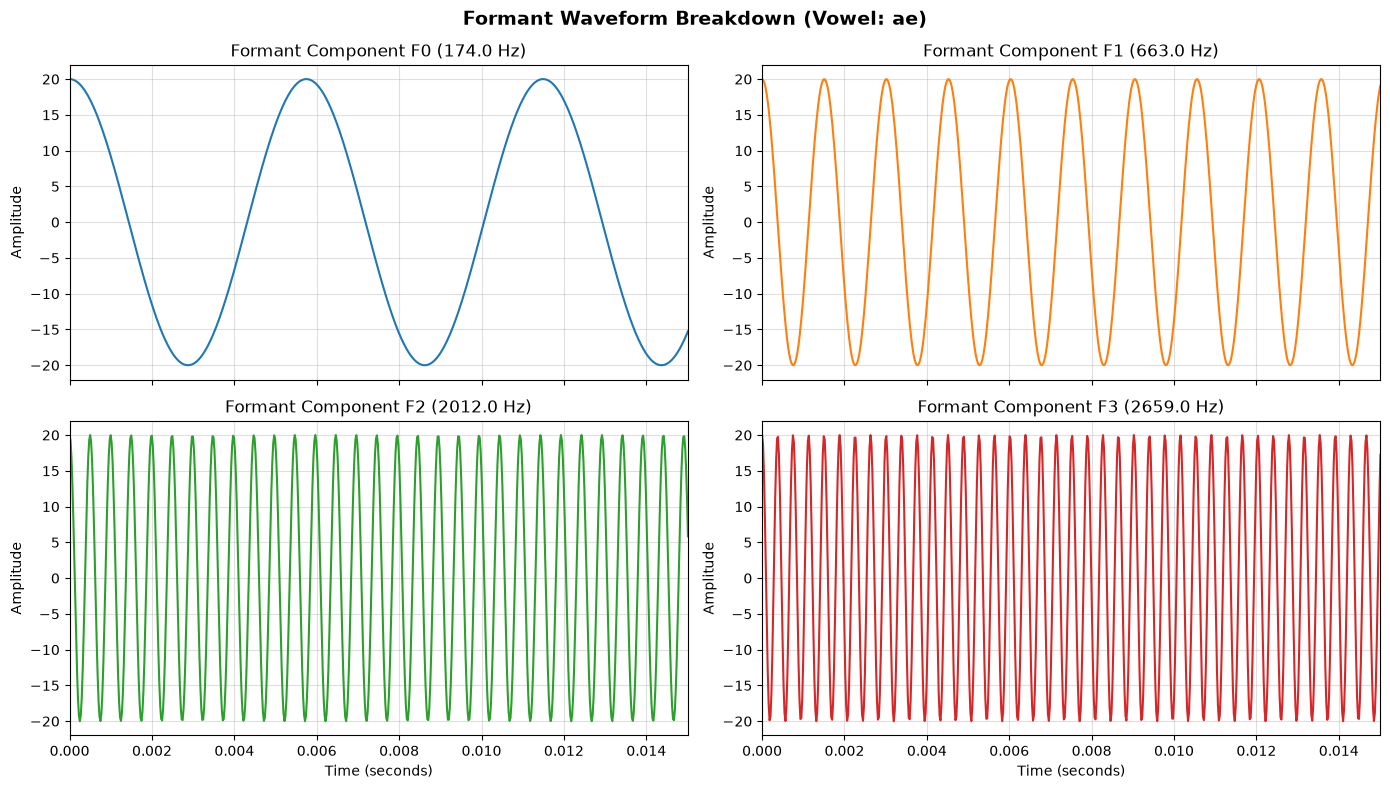

In [62]:
# --- 4-Up Visualization Block ---
fig, axs = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
fig.suptitle(f"Formant Waveform Breakdown (Vowel: {row.get('vowel', 'Unknown')})", fontsize=14, fontweight='bold')

# Plotting the first 4 formants (f0, f1, f2, f3)
axes_flat = axs.flatten()
for i in range(4):
    name = f'f{i}'
    freq = formant_frequencies[i]
    ax = axes_flat[i]
    
    # Zoom in heavily on the time axis to see individual cycles clearly
    ax.plot(time_, formant_waveforms[name], color=f'C{i}', linewidth=1.5)
    ax.set_title(f"Formant Component {name.upper()} ({freq:.1f} Hz)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.4)
    ax.set_xlim(0, 0.015)  # Display first 15 milliseconds

# Set shared X label at the bottom
for ax in axs[1, :]:
    ax.set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

That looks right. Now, let's listen to one.

In [63]:
audio_data = np.int16(formant_waveforms['f1'] * 32767)
display(ipd.Audio(audio_data, rate=sample_rate))

That...Is technically a sound at a frequency, but it doesn't inspire confidence.

Let's combine them.

In [64]:
synthesized_vowel = sum(formant_waveforms.values())

In [65]:
# normalize by loudest sound to fix clipping...
synthesized_vowel /= np.max(np.abs(synthesized_vowel))

In [66]:
audio_data = np.int16(synthesized_vowel * 32767)
display(ipd.Audio(audio_data, rate=sample_rate))

...Odd. That's an improvement—it sounds richer, and "round"-ish, somewhat like an "a"—but, compare it to our example...

In [67]:
example = df['path'].iloc[0]
audio, sr = lb.load(f'{example}.wav', sr=None)
ipd.Audio(audio, rate=sr)

Ours

- Sounds robotic;
- Doesn't immediately sound like an "a".

If we do the same thing with different formant values, we notice they _do_ have an effect. Here's another half-baked synthesis, this time of an "i" vowel.

In [68]:
# grab i vowel
row = df.iloc[834]
formant_frequencies_ih = [row['f0_ss'], row['f1_ss'], row['f2_ss'], row['f3_ss'], row['f4_ss']]
formant_names_ih = ['f0', 'f1', 'f2', 'f3', 'f4']

# light magic
formant_waveforms_ih = {
   name: 20 * np.sin(2 * np.pi * freq * time_)
    for name, freq in zip(formant_names_ih, formant_frequencies_ih)
}

In [69]:
synthesized_vowel_ih = sum(formant_waveforms_ih.values())

In [70]:
# normalize by loudest sound to fix clipping...
synthesized_vowel_ih /= np.max(np.abs(synthesized_vowel_ih))

In [71]:
audio_data = np.int16(synthesized_vowel_ih * 32767)
display(ipd.Audio(audio_data, rate=sample_rate))

In [72]:
example = df['path'].iloc[834]
audio, sr = lb.load(f'{example}.wav', sr=None)
ipd.Audio(audio, rate=sr)

Still robotic. But the intended "vowel" is clearly different; it _does_ subtly sound more like "ih" than "ah" to my ear.

So formant frequencies do have _something_ to do with vowels...Something went right.

But something else clearly went wrong. What?

## Bandpass Synthesis

TODO: Make this the tube model/source-filter section; vowels aren't the same as the simple sounds we studied before

I lied about infinity, earlier.

Or rather, it's not that _only_ F1-3 matter. It's that only F1-3 matter _for distinguishing vowels_: We need the other formants and resonances for a vowel to sound _human_.

Turns out, this is more like how voices work, anyway: The larynx produces a sound that, on its own, sounds like a hiss; that moving air gets "shaped" in your mouth to produce the sounds we know and love (and understand).

The shape of your mouth selects which resonances we hear; this, in turn, determines which vowel we perceive. When I say "a" and you say "a", we generate similar formant frequencies, _but our voices are still different_.

The first few formants determine the vowel; the rest determine _the sound of you_.

It's similar to the way a guitar sounds different from a violen. The same note played on a guitar sounds different on a violin. The reason is because, while the _note_ is the same, what we hear is not the pure note: It's the result of the note _ringing through the body of the instrument_. The string makes a sound when plucked; the sound bounces around the guitar or violin body; and what we hear is what bounces back out. Just like with the mouth, the shape of the instrument determines the resonances, and therefore, the quality, or **timbre**, of the instrument.

Your voice is exactly the same: Your larynx plucks the string. Your mouth shapes and amplifies the sound. We only need a few formants to tell _what_ you're saying—but we need all of them to hear _you_.

Unfortunately, we're out of luck as far as adding more formant frequencies: We've only got the four in our data set, and we can't exactly invent more at random.

Let's back up. The problem is that mixing four pure formants frequencies together is too "thin"; it leaves out all the infinity of other formants we need for it to sound like a voice. We can't make up infinity formants ourselves. Instead, we could start with a sound that has an infinite number of frequencies in it...And then _filter out_ everything except for what's around our formant values.

It won't be perfect—we'll be losing any richness around _other_ formants we don't have—but we'll get _infinitely more_ richness than we currently have. So it's worth a shot.

The downside is: This complicates things a bit. We need to:

- Start with a "rich enough" sound
- Find a way to remove some frequencies—...but not all
- Compute new vowels

When I write it like that, it doesn't seem so bad. Let's try it out.

**Note**: Need to introduce basics of sound, at this point; assume a background write-up covering

- Sound signals using NumPy
- Basic wave types
- Harmonics, explicitly deferring how we compute them
- Construction, Demo of deconstruction w/ above caveat
- Instrument and vocal timbre; perceived pitch vs texture

The important point/takeaway from this one will be instrument and vocal timbre.

To start, we need a sound to filter out. We'll start by generating some noise.

- TODO: Replace with glottal pulse train later

In [73]:
sample_rate = 44100
duration = 2.0
frequency = df.iloc[0]['f0_ss']
amplitude = 10

In [74]:
time_ = np.linspace(0, duration, int(duration * sample_rate), endpoint=False)

In [75]:
# uncorrelated uniform noise
noise = np.random.uniform(-amplitude, amplitude, len(time_))

There's [a lot to say about noise](https://allendowney.github.io/ThinkDSP2/chap04.html); turns out, there are different kinds. We're using the absolute simplest: A list of purely random numbers.

In [76]:
audio_data = np.int16(noise * 32767)
display(ipd.Audio(noise, rate=sample_rate))

Sounds like it looks.

One of the reasons our synthesized vowel sounded too robotic was because it contained _only_ four frequencies. In a real human voice, those are enough to distinguish vowels—but only if the others are there to give the voice its proper timbre.

Random noise—because it's random—contains _lots_ of frequencies. This means, even if we filter out most of them, we'll still have a _lot_ of random frequencies "near" the formants. This will make the vowel sound "richer", if not exactly like a voice.

Next, we need a way to remove frequencies from a sound. For this, you use a **filter**.

Our goal is to take noise, which as a little of every frequency, and remove almost everything, _except_ for

- Our formant frequencies, which will determine the vowel
- Frequencies nearby, which will add "texture" to the synthesizer, and make it sound fuller

We know which formant frequencies to use; those come from the dataset. We have a couple of decisions to make:

- How close is "nearby"? 50 Hz? 5000?
- Should all formants be equally strong? Or should the filter for, e.g., F2, produce a _weaker_ peak than the filter for F1?

The first number is the formant's **bandwidth**; the latter refers to its **gain**, or relative power. Both of these do matter; but since they're not included in our data, we'll set them based on known values...But we'll start with equal power.

A filter is a device that's able to take a sound, remove some frequencies, and pass the rest. Think of a speaker behind a door: You can't clearly hear higher frequencies, like voices or melodies, but you still feel the bass. In this case, the door is a **low pass filter**: It lets low-frequency bass tones through, but blocks the high ones.

In our case, we want to remove frequencies both lower _and_ higher than a specific frequency, plus or minus the range we determine. This is called a **bandpass** filter. The specific frequency range we specify is called the **passband**—the range of frequencies that the filter allows through.

In our case, we need one filter for each formant; we'll end up with a list of three different filters. This list of filters is called a **filterbank**, which is a list of bandpass filters like ours.

The code below creates one filter for each formant, then applies them to the noise we started with, leaving us with just the frequencies around the formants.

More precisely: We use [scipy.signal.iirpeak](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.iirpeak.html) to create three Butterworth filters, and then [scipy.signal.filtfilt](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.filtfilt.html) to perform [zero-phase filtering](https://ccrma.stanford.edu/~jos/fp/Zero_Phase_Filters_Even_Impulse.html).

Our goal is to retain the formant frequencies and the sounds immediately around them, but nothing else. In other words, we want thin _peaks_ at the formant frequencies, hence the use of [iirpeak](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.iirpeak.html), which allows us to specify the frequency to be retained ($w_{0}$, the first argument), as well as the [Q factor](https://en.wikipedia.org/wiki/Q_factor), which describes the degree of damping. This, in turn, determines the "ringing"/sustain quality of the retained frequency.

If none of that made sense, don't worry—we actually don't need this again.

In [77]:
# grab formant frequencies again
formant_frequencies_ss = df.iloc[0][['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']].values
formant_frequencies_ss

array([np.int64(174), np.int64(663), np.float64(2012.0),
       np.float64(2659.0), np.float64(3691.0)], dtype=object)

In [78]:
# define bandwidths; they grow wider as frequency grows
bandwidths = [130.0, 70.0, 60.0]

In [79]:
def vowel_filter(carrier, formant_frequencies, bandwidths):
    # accumulator for synthesized vowel
    synthesized_vowel = np.zeros_like(carrier)
    # apply filters to noise
    for freq, bw in zip(formant_frequencies, bandwidths):
        Q = freq / bw
        # get transfer function coefficients
        b, a = scipy.signal.iirpeak(freq, Q, fs=sample_rate)
        # convert to SOS sections
        sos = scipy.signal.tf2sos(b, a)
        # add result to accumulator
        synthesized_vowel += scipy.signal.sosfiltfilt(sos, carrier)
    return synthesized_vowel

In [80]:
synthesized_vowel = vowel_filter(noise, formant_frequencies_ss, bandwidths)

In [81]:
def play_vowel(synthesized_vowel):
    # normalize to prevent clipping
    synthesized_vowel /= np.max(np.abs(synthesized_vowel))

    audio_data = np.int16(synthesized_vowel * 32767)
    display(ipd.Audio(audio_data, rate=sample_rate))

In [82]:
play_vowel(synthesized_vowel)

In [83]:
example = df['path'].iloc[0]
audio, sr = lb.load(f'{example}.wav', sr=None)
ipd.Audio(audio, rate=sr)

This...Doesn't immediately sound better. Let's try an "ih" vowel.

In [84]:
# grab formant frequencies again
formant_frequencies_ss_ih = df.iloc[834][['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']].values
formant_frequencies_ss_ih

array([np.int64(179), np.int64(370), np.float64(2161.0),
       np.float64(2757.0), np.float64(3609.0)], dtype=object)

In [85]:
ih = vowel_filter(noise, formant_frequencies_ss_ih, bandwidths)

In [86]:
play_vowel(ih)

In [87]:
example = df['path'].iloc[834]
audio, sr = lb.load(f'{example}.wav', sr=None)
ipd.Audio(audio, rate=sr)

Not very human, but _definitely_ distinguishable. One more...

In [88]:
f_freqs_ss_uh = df.iloc[1390][['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']].values
f_freqs_ss_uh

array([np.int64(171), np.int64(670), np.float64(1178.0),
       np.float64(2566.0), np.float64(3641.0)], dtype=object)

In [89]:
uh = vowel_filter(noise, f_freqs_ss_uh, bandwidths)

In [90]:
play_vowel(uh)

In [91]:
example = df['path'].iloc[1390]
audio, sr = lb.load(f'{example}.wav', sr=None)
ipd.Audio(audio, rate=sr)

...All right. We're not building synthesizers with it, but—it's clear that formant frequencies absolutely have something to do with perceived vowel quality.

The results aren't great, but consider: This is the simplest _possible_ way to approach the problem, and these three "vowels" are, at least, distinguishable. By ear, it makes intuitive sense that an ML model should be able to use formant frequency as a classifier feature. 

We could make things more complicated and improve results with:

- A different carrier signal; it would be more correct to use an impulse train, for example.
- Dynamics; we're using steady state values _only_, so _all_ dynamic character in speech is lost. These dynamics are important—hence the Hillenbrand data's inclusion of 20/50/80 values in addition to steady-state—and we're leaving them out entirely.
- Better thought-out bandwidths; these are fairly arbitrary.

We've learned:

- Constructing a "vowel" with sinusoids at formant frequencies doesn't work.
- Filtering out sounds _except_ for formant frequences, with some noise...Kind of starts to work. The background noise is called the **source**, and the filters that strip away everything except the formant frequencies are called the, well, collective **filter**, yielding a **source-filter** model for vowels.
- Naive synthesis with bandpass filters isn't enough to get a convincing human sound; we're (apparently) missing overtones, dynamics, and lots of other stuff.
- ...But, it's clear formant frequencies, even naively applied, lead to distinguishable differences between synthesized vowels. It should be enough for an ML model to differenitiate between categories. 

## Inverting Construction

We've convinced ourselves that vowels do, indeed, have to do with formant frequencies; and have seen that the first three (in our case, four) are sufficient to distinguish vowels, even if it's not enough to synthesize a recognizably human sound.

That should convince us that formant frequencies are, in fact, useful for predicting vowels. That brings us back to the original question we had: What if Hillenbrand and friends _hadn't_ handed us a table of formant values? Or, what if we need to compute it ourselves from samples like those in the WAV data?

Plots of amplitude over time are of no use; we'd want to be able to plot the _frequencies_ in the sound, and how much _influence_ each one makes to it.

We created our vowel sounds in two ways:

- **Direct Synthesis**: Tahe the formant frequencies. Attach them to cosines. Slap them together. Not very good; simple.
- **Source Filtering**: Apply a bandpass filterbank to a noise bed. Better; more complicated.

At a glance, inverting the source-filter model seems...Hard. The direct synthesis approach produced a rather poor "vowel" sound, _but_:

- It's simple: It's basically a bunch of multiplication and addition, and even I know how to turn those around.
- The results _were_, technically, distinguishable. Maybe it _kind of_ works, but our ears don't detect it well; and reversing it might _kind of_ work, and give us a good starting point.

Here's what we'll do:

- Revisit the original "construction from frequencies" approach we took earlier.
- Re-express it using matrices.
- Manipulate the expression to derive an equation for the _frequencies_
- Use linear algebra to solve it

...Then, we'll see how well the solution works on both our cruddy vowel (it _should_ perfectly identify the four sinusoids we combined), and our fancier source-filtered ones (it should find power mostly, but not exclusively, around formant frequencies).

We started by observing the following:

- The dataset gives us formant frequencies. Sound waves are generated by air moving at a given frequency. Ergo, we can—maybe—synthesize a vowel by making sound waves at the appropriate frequencies.
- Sine waves can represent sound at a specific frequency. Stacking the right combination of sine waves can (maybe) give us a vowel sound.
- All we need is a list of included frequencies to create the new sound; that's enough to create a set of sine waves to synthesize.

We learned this doesn't really work for vowels, but it _does_ let us create genuinely complex waves that approximate piano or guitar chords, but without the richness of resonance through the instrument body.

Let's rewrite our code, expressing it mathematically along the way.

We started with formant frequencies—specifically, steady-state values. These were:

In [92]:
for name, freq in zip(formant_names, formant_frequencies):
    print(f'{name}: {freq} Hz')

f0: 174 Hz
f1: 663 Hz
f2: 2012.0 Hz
f3: 2659.0 Hz
f4: 3691.0 Hz


To say this in general: Call each frequency an  $f_{i}$, with $i \in \{0, 1, 2, ...\}$. The frequencies above are real, but in general, we can have $f \in \mathbb{C}$.

We then used each frequency to generate cosine waves, like below:

In [93]:
name = 'f1'
freq = formant_frequencies[1]

duration = 1
sample_rate = 44100

In [94]:
# first, generate a timeline and compute cosine wave
timeline_ = np.linspace(0, duration, int(duration * sample_rate), endpoint=False)
cosine_wave_ = np.cos(2 * np.pi * freq * timeline_)

(0.0, 0.015)

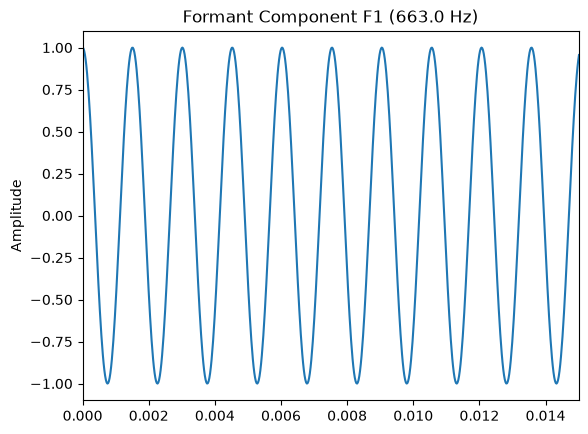

In [95]:
# one of the formant waves
plt.plot(timeline_, cosine_wave_)
plt.title(f"Formant Component {name.upper()} ({freq:.1f} Hz)")
plt.ylabel("Amplitude")
plt.xlim(0, 0.015)  # Display first 15 milliseconds

Mathematically, each equation has the form:

$$
g(f_{i}, a_{i}, t) = a_{i} \cos(2\pi f_{i} t + \phi) + C
$$

We only specified a frequency for each wave, and a uniform amplitude. In general, however, each $f_{i}$ is associated with 

- An **amplitude**, $a_{i} \in \mathbb{C}, \space i \in \{0, 1, 2, ...\}$;
- A **phase**, $\phi_{i}, \phi \in [0, 2\pi]$;
- A **DC offset**, $C \in \mathbb{R}$.
  - ...But we'll ignore this. Offsets contribute a _constant_ amount of extra power; constants don't change, so in the _frequency_ spectrum, it appears as 0 Hz signal; this leads to an additional spike 0 Hz in the DFT, _but nowhere else_; for our purposes, we're typically interested in the _alternating current_, or **AC**, since we're explicitly concerned with frequencies. 

Alternatively, can say we _did_ include phase and offset earlier, but set them to zero.

At this point, we might recall Euler's formula:

$$
A e^{i \omega t + \phi} = A(\cos(\omega t + \phi) + i \sin(\omega t + \phi)) 
$$


Observe that our cosine function is just $\operatorname{Re}(A_{i} e^{2\pi i f_{i} t})$.

Because the imaginary part of the complex exponential doesn't influence the real signal, this means we can use the complex exponential instead of cosine without altering our results from earlier; and because linear algebra is valid over arbitrary fields, we don't need to adjust our matrix algorithm, either.

Next, we combined each of our cosine functions by taking a simple sum. In code, that looked like:

In [96]:
synthesized_vowel_ih = sum(formant_waveforms_ih.values())

Simple. In math, using cosine:

$$
S_{out} = \sum_{i}^{N} a_{i} \cos(2\pi f_{i} t + \phi)
$$

...Less simple _looking_, but the same _thing_: Take the values of each function evaluated over $t$; sum them; return.

Using complex exponentials:

$$
S_{out} = \sum_{i}^{N} A_{i} e^{2\pi f_{i} t + \phi_{i}} + C_{i}
$$

...Where $S_{out}$ is the output signal.

Either way, we're simply taking a linear combination of the form:

$$
S_{out} = \sum_{i}^{N} A_{i} \mathbf{e}_{i}
$$

...Where $A_{i}$ are the amplitudes in frequency space, and $\mathbf{e}_{i}$ represents the complex exponentials. Again, we ignore $C_{i}$ without loss of generality.

This doesn't buy us anything new; I'm just emphasizing that, despite the gnarly exponent, we're just adding vectors. 

One hiccup. The above equations assume $t \in \mathbb{R}$; i.e.:

- They treat time as continuous;
- Nothing about the above has to do with _evaluation_.

This raises two corresponding problems:

- We're working with a computer; everything is discrete.
- We need to actually _compute_ these functions; we want to _hear_ something, after all.

Fortunately, we already _did_ this earlier, so there's nothing new; let's just describe it formally.

To represent our conceptual solution with matrices—or arrays, for that matter—we first need to discretize time.

Note that our complex exponentials are fully characterized by the 4-tuple $(f_{i}, A_{i}, \phi_{i}, C_{i})$, described above. Evaluation is essentially equivalent to _sampling_ the continuous, "analog" signal defined by the underlying function by "measuring" it at select instants over the interval $t$; it's up to us to determine _how_ to perform that sampling.

We're solving the synthesis problem, where we evaluate each sinusoid on a half-open interval $[0, d)$ of user-specified length. Thus, each complex exponential expands to an evaluated vector of length $k = f_{s} \cdot d$. In our case, we emulated a sampling rate of 44,100 Hz ($f_{s}$) over three seconds ($d$). 

These column vectors are then collected into a matrix $M$. Each column contains the values of one of our complex exponentials evaluated along the timeline.

Finally, we take the linear combination of the result, scaling each column vector by its amplitude. Conveniently, this is the definition of the matrix-vector dot product of $M$ with our amplitude vector, $\mathbf{a}$. 

This leads to the matrix representation below:

$$
M\mathbf{a} = S_{out}
$$

Thus:

$$
M\mathbf{a} = 
\begin{bmatrix}
e^{2\pi i f_{0} t_{0}} &  e^{2\pi i f_{1} t_{0}}  & \ldots & e^{2\pi i f_{2} t_{0}}\\
e^{2\pi i f_{0} t_{1}} &  e^{2\pi i f_{1} t_{1}}  & \ldots & e^{2\pi i f_{2} t_{1}}\\
e^{2\pi i f_{0} t_{2}} &  e^{2\pi i f_{1} t_{2}}  & \ldots & e^{2\pi i f_{2} t_{2}}\\
& \ldots
\end{bmatrix}
\begin{bmatrix}
A_{0} \\
A_{1} \\
A_{3} \\
\ldots
\end{bmatrix} =
A_{0}
\begin{bmatrix}
e^{2\pi i f_{0} t_{0}} \\
e^{2\pi i f_{0} t_{1}} \\
e^{2\pi i f_{0} t_{2}} \\
\ldots
\end{bmatrix} + \ldots 
A_{N}
\begin{bmatrix}
e^{2\pi i f_{N} t_{0}} \\
e^{2\pi i f_{N} t_{1}} \\
e^{2\pi i f_{N} t_{2}} \\
\ldots
\end{bmatrix} =
\sum_{i}^{N} A_{i} e^{2 \pi i f_{i} t_{j}} =
S_{out}
$$

...We don't have _true_ equality with what I wrote above; keep in mind that the matrix representation discretizes the continuous function of $t$ we started with.

In any case, we see that the matrix equation on the left produces our signal on the right. Let's package the math up in some code, and use it.

In [97]:
class SimpleSynthesizer:

    def __init__(self, amplitudes, frequencies, duration: float = 1.0, sampling_rate: int = 44100):
        self.amplitudes = np.array(amplitudes)
        self.frequencies = frequencies
        self.duration = duration
        self.sample_rate = sample_rate
        self.evaluated = None

    def synthesize(self):
        if self.evaluated:
            return self.evaluated
        # produce M
        ts = np.linspace(0, self.duration, int(self.duration * self.sample_rate), endpoint=False)
        partial_args = np.outer(ts, self.frequencies)
        # compute exponentiated matrix
        M = np.exp(2 * np.pi * 1j * partial_args)
        # dot with amplitudes
        self.evaluated = np.dot(M, self.amplitudes)
        
        return self.evaluated

In [98]:
amps = np.array([0.6, 0.25, 0.1, 0.05, 0.1])
fs = [100, 200, 300, 400]
framerate = 11025
ts = np.linspace(0, 1, framerate, endpoint=False)

In [99]:
res_ = SimpleSynthesizer(
    # uniform amplitudes
    amplitudes=[10 for f in formant_frequencies],
    frequencies=formant_frequencies,
).synthesize()

In [100]:
# ignore warning; we have no imaginary data of meaning
play_vowel(res_)

/var/folders/zd/whvxk10d74148p1krxw0hq000000gn/T/ipykernel_80366/1867429590.py:5: ComplexWarning: Casting complex values to real discards the imaginary part
  audio_data = np.int16(synthesized_vowel * 32767)


Let's try a B♭ Major 6 chord:

- B♭ (Root): 233.08 Hz
- D (Major 3rd): 293.66 Hz
- F (Perfect 5th): 349.23 Hz
- G (Major 6th): 392.00 Hz

In [101]:
bm6_freqs = [233.08, 293.66, 349.23, 392.00]
bm6_amps = np.array([0.6, 0.25, 0.1, 0.05])
bm6 = SimpleSynthesizer(bm6_amps, bm6_freqs).synthesize()

play_vowel(bm6)

/var/folders/zd/whvxk10d74148p1krxw0hq000000gn/T/ipykernel_80366/1867429590.py:5: ComplexWarning: Casting complex values to real discards the imaginary part
  audio_data = np.int16(synthesized_vowel * 32767)


It works.

More importantly—this is all we need to go in the reverse direction.

If we're given $S_{out}$, which specifies $t$, we can solve for $a$ by selecting a set of $N$ frequencies we think will suffice to construct the signal and solving a **system of equations**. 

$$
\begin{aligned} 
y = Ma \implies  
\begin{bmatrix} 
y_0 \\ 
y_1 \\ 
y_2 \\ 
\vdots \\ 
y_{N-1} 
\end{bmatrix} = 
\begin{bmatrix} 
e^{2\pi i f_{0} t_{0}} & e^{2\pi i f_{1} t_{0}} & e^{2\pi i f_{2} t_{0}} & \dots & e^{2\pi i f_{N-1} t_{0}} \\ 
e^{2\pi i f_{0} t_{1}} & e^{2\pi i f_{1} t_{1}} & e^{2\pi i f_{2} t_{1}} & \dots & e^{2\pi i f_{N-1} t_{1}} \\ 
e^{2\pi i f_{0} t_{2}} & e^{2\pi i f_{1} t_{2}} & e^{2\pi i f_{2} t_{2}} & \dots & e^{2\pi i f_{N-1} t_{2}} \\ 
\vdots & \vdots & \vdots & \ddots & \vdots \\ 
e^{2\pi i f_{0} t_{N-1}} & e^{2\pi i f_{1} t_{N-1}} & e^{2\pi i f_{2} t_{N-1}} & \dots & e^{2\pi i f_{N-1} t_{N-1}} 
\end{bmatrix} 
\begin{bmatrix} 
A_{0} \\ 
A_{1} \\ 
A_{2} \\ 
\vdots \\ 
A_{N-1} 
\end{bmatrix} 
\end{aligned}
$$


Instead of multiplying forward, we use $M$, which contains data about our frequencies, to solve for $a$, their corresponding amplitudes.

...Can also be written as:

$$
\begin{cases} 
A_0 e^{2\pi i f_0 t_0} + A_1 e^{2\pi i f_1 t_0} + A_2 e^{2\pi i f_2 t_0} + \dots + A_{N-1} e^{2\pi i f_{N-1} t_0} = y_0 \\ 
A_0 e^{2\pi i f_0 t_1} + A_1 e^{2\pi i f_1 t_1} + A_2 e^{2\pi i f_2 t_1} + \dots + A_{N-1} e^{2\pi i f_{N-1} t_1} = y_1 \\ 
A_0 e^{2\pi i f_0 t_2} + A_1 e^{2\pi i f_1 t_2} + A_2 e^{2\pi i f_2 t_2} + \dots + A_{N-1} e^{2\pi i f_{N-1} t_2} = y_2 \\ 
\vdots \\ 
A_0 e^{2\pi i f_0 t_{N-1}} + A_1 e^{2\pi i f_1 t_{N-1}} + A_2 e^{2\pi i f_2 t_{N-1}} + \dots + A_{N-1} e^{2\pi i f_{N-1} t_{N-1}} = y_{N-1} 
\end{cases}
$$

...Or, more compactly:

$$
\sum_{k=0}^{N-1} A_k e^{2\pi i f_k t_n} = y_n \quad \text{for } n = 0, 1, \dots, N-1
$$

Looks ugly, but [numpy.linalg.solve](https://numpy.org/devdocs/reference/generated/numpy.linalg.solve.html) does this for us.

In [102]:
class SimpleAnalyzer:

    def __init__(self, signal, frequencies, times):
        self.frequences = frequencies
        self.times = times
        self.signal = signal

    def analyze(self):
        partial_args = np.outer(self.times, self.frequencies)
        M = np.exp(2 * 1j * np.pi * partial_args)
        a = np.linalg.solve(M, self.signal)
        return a

This technically works, but is cruddy to use. I have to pass frequencies and times...It would be better to just send the _signal_.

We'll make assumptions:

- Your sample is **one unit** of time long. We don't care _what_ unit of time; we'll just say, however long your signal is, _that's_ the unit of time, and we have one of them.
- Your sampling rate is **equal to the length of the sample**. I.e., your sampling rate was $N$.

If your sampling rate _wasn't_ $N$, the DFT produces the same results—but the resolution of your _interpretation_ will change. We'll come back to that.

Making these assumptions lets us rewrite things more succinctly.

In [103]:
class SimpleAnalyzer:

    def __init__(self, signal):
        self.signal = signal

    def analyze(self):
        N = len(self.signal)
        times = np.arange(N) / N
        frequencies = np.arange(N)
        
        partial_args = np.outer(times, frequencies)
        M = np.exp(2 * np.pi * 1j * partial_args)
        return np.linalg.solve(M, self.signal)

This is the answer were looking for: Turning a sound into a spectrum _is_ possible.

_And we already know how to do it_.

...Kind of.

If you try to actually run this...It doesn't work. 

Or, it does—but you'll wonder what broke, because it'll take forever; it takes _minutes_ to compute $M$. And that's not even the slow part. 

So, a solution _exists_. But this one is useless.

A couple other caveats:

- In the forward direction, the number of sinusoids $N$ bounds the possible complexity of our output. A single component is a pure sine wave; a handful is like a chord; a few hundred could start to sound like a guitar if you choose them correctly. Bigger $N$ = more complicated sound potential.
- In the reverse, $N$ corresponds to the number of frequencies in an input we can _pick out_. Remember: We're solving an equation that asks: _how much does each of these complex exponentials contribute to the input wave_?
  - If you hand me a signal that contains the frequencies 100 Hz, 150 Hz, and 200 Hz, but only use sinusoids at 100 Hz and 200 Hz, you completely miss the component at 150 Hz. If you try to recreate the original input, it won't work; you'll be missing a whole frequency component. In this way, $N$ determines _resolution_ of the analysis algorithm: Higher $N$ means we can pick out more frequencies, with smaller differences between them.

Most real sounds need large $N$ to be faithfully reproduced. We also need to sample at 44,100 Hz to account for human hearing. This leads to large numbers pretty quickly; we couldn't even run this solution on our fake, one-second example. That was 44,100, the minimum, and _already_ broke.

Solving the system of equations directly is $O(n^{3})$ time, in general; there's no way to speed this approach up. It's entirely useless.

That's a bummer, but the matrix equation reveals an alternative approach. If we could find the inverse of $M$, then we could write:

$$
\begin{aligned}
& S_{out} = M\mathbf{a} \\
& M^{-1}S_{out} = M^{-1}M\mathbf{a} \\
& M^{-1}S_{out} = I{a} = a
\end{aligned}
$$

If we have $M^{-1}$, solving the system of equations reduces to a simple matrix multiplication.

In this case, we just compute a dot product between each column of $M^{1}$ and $S_{out}$; that's work proportional $N$ operations per $N$ elements of $S_{out}$, for time complexity of $O(n^{2})$, since our matrix is square.

That's a huge improvement...But computing inverses is generally expensive—[at least](https://cstheory.stackexchange.com/questions/3921/what-is-the-actual-time-complexity-of-gaussian-elimination) $O(n^{3})$, often worse in practice.

Let's take a big step back and figure out what $M^{-1}$ does physically: then, we might be able to construct it directly.

We know $M^{-1}$ is the reverse of $M$; and $M$ contains the values of each constituent complex exponential. So, $Ma$ computes a weighted combination of signals with amplitudes.

That means, for  $M^{-1}S_{out}$ to somehow compute $a$, $M^{-1}$ must eat our signal; somehow test it against the same frequencies contained in $M$ (or else it couldn't reverse it); and then report a measurement of how much each one contributes to $S_{out}$. 

More directly: $M^{-1}$ must correlate each frequency in $M$ against $S_{out}$; and spit out a list measuring how much each it's correlated to each frequency.

You _could_ build a machine that does this. Imagine a black box, containing a row of tuning forks, ranging from 1 Hz to...N Hz. It's a really big box. 

Each fork is perfectly sensitive—it resonates to a specific frequency, and _only_ that frequency.

The tine of each fork is inside the box; some portion of the handle sticks out. When a fork resonates, the handle shakes. We can measure how much to determine how strongly a fork is vibrating.

Now: If we play a sound through the box, it will cause some forks to vibrate—but _only_ those that respond to frequencies contained within the sound, in proportion to how strongly it contributes. 

Measuring how much each handle moves gives us a list of amplitudes associated with each frequency.

Assuming you have enough forks, you could decompose _any_ sound this way. If, later, you ring each fork exactly the amount you recorded, you'll reproduce the input sound—the correlation are enough to perfectly reconstruct the analog signal from a digital representation.

Each tuning fork in the box responds to a _single_ frequency: That means we can represent each tuning fork with a specific complex exponential.

Our complex exponentials and input signal are represented as vectors. We can determine the similarity between two vectors, like our machine measures the similarity between a sound and a tuning fork, by checking the angle between them: If two vectors overlap perfectly, they're the same (up to scale), and the angle between them is zero degrees, and they line up perfectly. If they don't overlap at all, they end up at ninety degree angles, or orthogonal, to one another.

The cosine of this angle is called **cosine similarity**, and measures...Well, similarity. It turns out cosine similarity is equivalent to **correlation** (...of mean-centered, variance-normalized vectors).

...But, since we're using complex numbers, we have to use an [inner product](https://en.wikipedia.org/wiki/Inner_product_space), instead; remember to take the complex conjugate of the second operand (_discussed in deep dive on complex exponentials and roots of unity, to precede this section_).

To check how much a single complex exponential overlaps our signal, we compute:

- TODO: LaTeX

To compute how much every complex exponential overlaps our signal, all at once, we build a matrix, and compute:

- TODO: LaTeX

...But the right side of this is $a$; the vector on the left is $S_{out}$; so the matrix must be $M^{-1}$, the matrix that correlates each of our test frequencies with the input signal.

So it turns out we _can_ build the inverse $M^{-1}$.

It gets better. To use the numbers $M^{-1}$ spits out and reconstruct the signal later, we need to scale each test frequency in $M^{-1}$ by the amplitudes it produced. So, we take every row in $M^{-1}$; take its dot product with $a$; and sum the result.

- TODO: LaTeX

In matrix form, that looks like this:

- TODO: LaTeX

...But this is exactly the $M$ we started with: The _rows_ of $M^{-1}$ correspond to the _columns_ of $M$.

Look again: Transposing each row of $M^{-1}$ produces each of the _columns_ of $M$. In other words, $M^{-1} = M^{T}$.

All we have to do to invert $M$ is _swap its entries_. That means we can implement our quadratic algorithm right away.

A quick note on transposes. With a real matrix, you simply flip entries along the diagonal. If the matrix is complex, like $M$, we both transpose entries, _and_ take the complex conjugate of each entry. The result of these two operations is called the **conjugate transpose**, but I prefer the quantum mechanical parlance of "[Hermitian adjoint](https://en.wikipedia.org/wiki/Hermitian_adjoint)".

Anyway, that last expression is curious: $M^{-1} = M^{T}$. This is only true when $M$ is orthogonal (or unitary). Let's review what that means.

## Orthogonality Review

A matrix is **orthogonal**, or **unitary** if complex, if all of its columns are perpendicular. In other words: If you can show all of a matrix's columns are at ninety degrees from each other, you've shown it's unitary; and if it's unitary, its transpose equals its own inverse.

The simplest example of an orthogonal matrix is:

$$
\begin{bmatrix}
1 & 0 \\
0 & 1
\end{bmatrix}
$$

...Which represents a basis for the $xy$-plane. We can see that $\hat{\imath}$ and $\hat{\jmath}$ are perpendicular because...Well, we have eyes, but numerically, we confirm by testing that their dot product is zero.

In [104]:
i_hat = np.array([1, 0])
j_hat = np.array([0, 1])
np.dot(i_hat, j_hat)

np.int64(0)

We also know they each have length one because each only has one component, of length one.

We can verify with NumPy.

In [105]:
np.linalg.norm(i_hat)

np.float64(1.0)

In [106]:
np.linalg.norm(j_hat)

np.float64(1.0)

An orthogonal matrix whose vectors are all of length one is called **orthonormal**. Unitary matrices are automatically orthonormal.

In general, you check for length using the $L^{2}$ norm, or Euclidean distance, applied to the vector's components. If a vector $\mathbb{v}$ is a unit vector, then:

$$
1 = \lVert v_{i} \rVert
$$

...In our case:

$$
\begin{aligned}
& \hat{\imath} = (1, 0) \to \lVert \hat{\imath} \rVert = \sqrt{1^{2} + 0^{2}} = 1 \\
& \hat{\jmath} = (0, 1) \to \lVert \hat{\imath} \rVert = \sqrt{0^{2} + 1^{2}} = 1
\end{aligned}
$$

Orthonormal matrices are nice; they preserve lengths and volumes under transformation due to their normality, _and_ their inverse is equal to their transpose. That makes their transformations nicely reversible, and fast to compute.

Again: $M^{-1} = M^{T}$ is true if and only if a the columns of a matrix are orthogonal. Since we know $M^{-1} = M^{T}$, the columns of $M$ must be orthogonal, and so the complex exponentials comprising $M$ must be orthogonal.

...That's a bit unexpected: What does it mean for complex exponentials to be perpendicular?

Intuitively, it means that, when we decompose a signal with our tuning forks, we can be 100% sure that the measurement taken by a tuning fork is accurate: There's a 0% chance that some other fork is also ringing. There's no _overlap_ in the sensitivity of each fork, in other words.

In other words: each fork's measurement is completely independent of the others.

This is the key insight. The fact that there's no overlap between complex exponentials is the clue: It suggests that, if two complex exponentials are orthogonal, their inner product is zero. That's a bit abstract, but makes more sense than "perpendicular waves".

This turns out to help make things clearer. Consider the partial inner product, _before_ we take the sum: If we multiply two sinusoids at different frequencies, we generate a perfectly symmetrical curve. 

Remember: This is what it looks like _right before_ we actually take the dot product and add things up. Doing that equates to summing the areas under those curves—which is the continuous version of what we do when we take an inner product—and you can see that they cancel out.

If the frequencies overlap, however, the area is positive, because we end up _squaring_ the signal; wherever the original is negative, the product is positive; and wherever it was positive, it's now bigger.

In [111]:
# TODO: 2-up

It's actually _not_ relevant to our case, because we're dealing with a discrete number of samples...But a straightforward evaluation of the integrals over a period proves this is the case.

In [112]:
# TODO: SymPy

The same idea proves the columns of our matrix are exactly orthogonal.

- TODO: Exposition of [proof](https://ccrma.stanford.edu/%7Ejos/mdft/Orthogonality_DFT_Sinusoids.html)

This is sort of a big deal. We said we'd build this "janky" version first; see how it breaks against the "fancier" synthesized vowel we created; and then go from there.

This result shows that we don't need to do that, at all. Not "might not"—provably not. This algorithm decomposes _any_ signal into correlations with the frequency set. It says nothing about the input.

We're already most of the way there: All that's left is implementation.

Because we know $M$ is orthogonal directly, and we can use $M^{-1} = M^{T}$ to compute the more efficient solution.

In [113]:
class SimpleAnalyzer:

    def __init__(self, signal):
        self.signal = signal

    def analyze(self):
        N = len(self.signal)
        times = np.arange(N) / N
        frequencies = np.arange(N)
        partial_args = np.outer(times, frequencies)
        M = np.exp(2 * np.pi * 1j * partial_args)
        # remember: M is complex, take conjugate transpose
        return M.conj().transpose().dot(self.signal) / N

This is technically better, but alas...You wouldn't be able to tell. It's _still_ too slow to run on our entire, measly, one-second dummy sound.

...But it _does_ work if we run it on a tiny slice.

In [108]:
bm6_short = SimpleSynthesizer(bm6_amps, bm6_freqs, duration=0.1).synthesize()

In [114]:
amps = SimpleAnalyzer(bm6_short).analyze()
amps

array([0.00496394+0.00792141j, 0.00516999+0.00825535j,
       0.00539464+0.00861878j, ..., 0.00443672+0.00706426j,
       0.00459905+0.0073286j , 0.00477425+0.00761348j], shape=(4410,))

Lovely. Let's see if we can find a way to visualize this thing.

Our analysis function assumes a sampling rate of $N$ Hz. We need to convert that to our _actual_ sampling rate for the plot to make sense.

In [142]:
N = len(bm6_short)
plot_frequencies = np.arange(N) * sample_rate / N

In [124]:
bm6_freqs

[233.08, 293.66, 349.23, 392.0]

In [127]:
bm6_amps

array([0.6 , 0.25, 0.1 , 0.05])

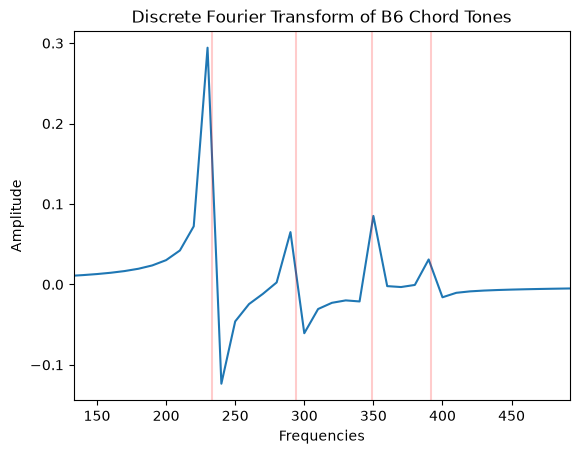

In [143]:
plt.plot(plot_frequencies, amps)
plt.xlim(min(bm6_freqs) - 100, max(bm6_freqs) + 100)
plt.title("Discrete Fourier Transform of B6 Chord Tones")
plt.ylabel("Amplitude")
plt.xlabel("Frequencies")

for freq in bm6_freqs:
    plt.axvline(x=freq, linestyle='-', alpha=0.2, color='red')

This is a plot of the relative amplitudes of the constituent frequencies of our chord tone, with vertical bars at the frequencies we used to recreate it.

Lo: A perfect analysis of the sound we sent it.

This thing has a name: We've implemented the [discrete Fourier transform](https://en.wikipedia.org/wiki/Discrete_Fourier_transform), or DFT.

It's arguably the most important technology of the modern era—and surely one of the deepest ideas.

A couple of technical observations:

- TODO: zero padding, smoothness, sampling rate (44,100 is extraordinary overkill), 

This technically answers the question we started with: _Can we see the frequencies within a sound?_

**Yes**—we can. Somewhat shockingly, we don't need to invert the source-filter approach at all; our solution works against the synthesized vowel, as well.

In [135]:
# TODO: 0.1s synthesized vowel, show plot, more frequencies due to noise

One hiccup. Our formant data contains frequencies measured at 20%, 50%, and 80% development, as well as steady state. Our analysis function shows us which frequencies are in the sound...But does _not_ tell us when they occur. Information about the _sequence_ of frequencies that characterize each formant are completely lost.

It wasn't obvious that would happen, but now that we're here...We'll need a way to recover that.

The solution: Chop the input signal into frames, analyze each frame, and inspect the spectrum of each result to see which frequencies occurred during that specific window of time.

This is the [Short Time Fourier Transform](https://en.wikipedia.org/wiki/Short-time_Fourier_transform), and we'll implement it next.

## Fast Fourier Transform

...BUt first: the whole point of spectrograms is creating one for every recording in our dataset, so we can pass them on to a CNN.

Our analysis function is good enough to prove a point. But it'll break catastrophically if we try to use it for what we set out to do.

Our implementation above is $O(n^{2})$, and it's well-known that quadratic time is...Impractical, at best.

Ideally, we'd find a $O(N \log N)$ algorithm; that would actually be practical.

Whenever faced with a quadratic algorithm, we should instinctively search for a [divide and conquer](https://en.wikipedia.org/wiki/Divide-and-conquer_algorithm) solution; recursive implementations often achieve the linearithmic bound.

The FFT has such a well-known solution, the [Cooley-Tukey algorithm](https://en.wikipedia.org/wiki/Cooley–Tukey_FFT_algorithm).

It's based on the Danielson-Lanczos lemma, provided by Allen Downey in [Think DSP 2](https://allendowney.github.io/ThinkDSP2/chap07.html#dft) as follows:

> The key to the FFT is the Danielson-Lanczos lemma:
>
> $DFT(y)[n] = DFT(e)[n] + \exp(-2 \pi i n / N) DFT(o)[n]$
>
> Where $DFT(y)[n]$ is the $n$th element of the DFT of $y$; $e$ is the even elements of $y$, and $o$ is the odd elements of $y$.
>
> This lemma suggests a recursive algorithm for the DFT:
>
> 1. Given a wave array, $y$, split it into its even elements, $e$, and its odd elements, $o$.
>
> 2. Compute the DFT of $e$ and $o$ by making recursive calls.
>
> 3. Compute $DFT(y)$ for each value of $n$ using the Danielson-Lanczos lemma.

Here is his solution:

In [145]:
# from: https://colab.research.google.com/github/AllenDowney/ThinkDSP2/blob/main/soln/chap07.ipynb#scrollTo=1c354c01
def fft(ys):
    N = len(ys)
    if N == 1:
        return ys
    
    He = fft(ys[::2])
    Ho = fft(ys[1::2])
    
    ns = np.arange(N)
    W = np.exp(-1j * PI2 * ns / N)

    # TODO: explain tile, periodicity of DFT
    return np.tile(He, 2) + W * np.tile(Ho, 2)

We won't belabor the point; from now on, we'll use [NumPy's fft](https://numpy.org/doc/stable/reference/routines.fft.html#module-numpy.fft) anyway.

The point is: This is possible, and makes it fast enough to use.

Watch the [Reducible video on the FFT](https://www.youtube.com/watch?v=h7apO7q16V0) for a proper exposition.

What we will do is prove the $O(N \log N)$ bound; turns out to be easy.

The Danielson-Lanczos lemma is:

$DFT(y)[n] = DFT(e)[n] + \exp(-2 \pi i n / N) DFT(o)[n]$

...Which is just a recurrence relation of the form:

$T(n) = a \, T\left(\frac{n}{b}\right) + f(n)$

...With:

- TODO: Re-express lemma, etc.

...Because $\exp(-2 \pi i n / N)$ is a _constant_, corresponding to a [root of unity](https://en.wikipedia.org/wiki/Root_of_unity). In the context of the FFT, these are often called [twiddle factors](https://en.wikipedia.org/wiki/Twiddle_factor) (seriously).

TODO: Complete...